# UKM Live Notulen — Code-Switching ASR (Indonesia + English)
**COMP6822001 Speech Recognition — Final Project**

Notebook ini dipakai untuk **training, evaluasi, dan export** model. Aplikasinya sendiri (real-time, di Vercel) **tidak** jalan di Colab — model hasil notebook ini di-export ke ONNX lalu dijalankan **di browser user** (Transformers.js), jadi inference tetap lokal di device user dan tidak memakai external ASR API.

| Bagian | Isi | Untuk laporan bagian |
|---|---|---|
| 1 | Setup & config | 4. Implementation |
| 2 | Dataset (FLEURS id/en + synthetic code-switch + rekaman UKM sendiri) | 5. Dataset |
| 3 | **MFCC manual dari nol** + validasi vs librosa | 2. Fundamentals, 3. Preprocessing |
| 4 | **Justifikasi 13 vs 12 koefisien** (eksperimen speaker ID GMM) + VAD pakai c0 | 2, 5 |
| 5 | Baseline Whisper pretrained (WER, CER, RTF) | 5. Baseline |
| 6 | Fine-tune Whisper-base untuk code-switching | 4. Model |
| 7 | Evaluasi: baseline vs fine-tuned, kondisi noise (babble meeting) | 5. Experiment |
| 8 | Simulasi streaming: partial transcript, latency, label speaker dari MFCC | 3. Real-time pipeline |
| 9 | Error analysis (substitution/deletion/insertion) | 5. Error analysis |
| 10 | Export ONNX + quantize → Hugging Face Hub → dipakai web app di Vercel | 4. Deployment |

> **Runtime → Change runtime type → T4 GPU** sebelum mulai.

## 1. Setup

In [3]:
# Versi di-pin supaya training + export ONNX konsisten (sudah dites).
!pip -q install "transformers==4.46.3" "datasets==3.1.0" "optimum[onnxruntime]==1.23.3" \
    "accelerate==1.1.1" jiwer librosa soundfile scikit-learn sentencepiece sacrebleu
# Colab sudah memasang 'diffusers' versi baru yang tidak cocok dengan versi pin di atas
# (error get_cached_repo_tree / Dinov2WithRegistersConfig saat export ONNX). Kita tidak butuh diffusers -> hapus.
!pip -q uninstall -y diffusers
# Kalau setelah install muncul error import -> Runtime > Restart session, lalu jalankan dari cell berikutnya.

In [4]:
import os, time, json, random, shutil, functools
import numpy as np, matplotlib.pyplot as plt, torch, scipy.fftpack
import librosa, jiwer, pandas as pd
from datasets import load_dataset, Audio, Dataset, concatenate_datasets, Features, Value

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ====================== CONFIG ======================
SR          = 16000
N_MFCC      = 13          # c0..c12 (lihat Bagian 4 untuk justifikasi)
BASE_MODEL  = "openai/whisper-base"   # target deploy di browser
COMPARE_MODEL = "openai/whisper-small" # pembanding akurasi (tidak dideploy)
LANGUAGE    = "indonesian"            # bahasa "matrix" untuk code-switching
MAX_STEPS   = 1500                    # ~20-40 menit di T4 untuk whisper-base (termasuk eval)
SEED        = 42

# Opsional (sangat disarankan): rekaman UKM kalian sendiri di Google Drive
#   OWN_DATA_DIR/  -> *.wav (16 kHz mono) + metadata.csv (kolom: file_name,transcription), tiap clip <= 30 detik
#   SPEAKER_DIR/   -> SPEAKER_DIR/<nama_orang>/*.wav  (min. 6 clip/orang) untuk eksperimen 13 vs 12
OWN_DATA_DIR = "/content/drive/MyDrive/ukm_asr/dataset"
SPEAKER_DIR  = "/content/drive/MyDrive/ukm_asr/speakers"

HF_REPO = "jennigwen/whisper-base-ukm-codeswitch"   # ganti USERNAME
FT_DIR  = "/content/whisper-base-ukm-cs"
# ====================================================
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

torch 2.11.0+cu130 | CUDA: True


In [3]:
# Mount Drive kalau pakai data sendiri (skip kalau belum punya)
try:
    from google.colab import drive; drive.mount("/content/drive")
except Exception as e:
    print("Bukan di Colab / skip mount:", e)

Mounted at /content/drive


## 2. Dataset

Tidak ada dataset publik Indonesia–Inggris code-switching yang bebas & siap pakai (dataset di paper code-switching ID-EN tidak dirilis publik; dataset komersial berbayar). Jadi strateginya **3 sumber**:

1. **FLEURS `id_id`** (Google, CC-BY 4.0) — speech Indonesia terbaca, ~3.6k utterance.
2. **FLEURS `en_us`** — speech Inggris.
3. **Synthetic code-switching**: gabungkan 1 utterance Indonesia + 1 utterance Inggris (≤ 30 detik) → model belajar pindah bahasa di tengah audio tanpa diterjemahkan.
4. **Rekaman UKM sendiri** (paling penting untuk *real-world*): rekam meeting/simulasi meeting UKM (dengan izin), potong ≤ 30 detik, transkrip manual. **Test set utama diambil dari sini** karena ini domain target user sebenarnya.

> Jawaban untuk dosen "dataset dari mana": pretrained Whisper = pengetahuan umum; FLEURS + synthetic CS = adaptasi ke ID↔EN; rekaman UKM = adaptasi & evaluasi domain target.

In [4]:
def load_fleurs(lang, split):
    # Coba parquet branch dulu (tanpa loading script), fallback ke repo default.
    try:
        ds = load_dataset("parquet", split=split, data_files={split:
              f"hf://datasets/google/fleurs@refs%2Fconvert%2Fparquet/{lang}/{split}/*.parquet"})
    except Exception as e:
        print("parquet gagal, fallback:", repr(e)[:200])
        ds = load_dataset("google/fleurs", lang, split=split, trust_remote_code=True)
    ds = ds.cast_column("audio", Audio(sampling_rate=SR))
    ds = ds.rename_column("raw_transcription", "text")
    return ds.select_columns(["audio", "text"])

id_train, id_test = load_fleurs("id_id", "train"), load_fleurs("id_id", "test")   # train parquet ~2 GB, sabar
# EN cukup pakai split validation (~400 utt) supaya tidak download 2 GB lagi
en_train, en_test = load_fleurs("en_us", "validation"), load_fleurs("en_us", "test")
print(id_train, id_test, en_train, en_test, sep="\n")
print("Contoh:", id_train[0]["text"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


id_id/train/0000.parquet:   0%|          | 0.00/2.09G [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

id_id/test/0000.parquet:   0%|          | 0.00/543M [00:00<?, ?B/s]

Generating test split: 0 examples [00:00, ? examples/s]

en_us/validation/0000.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

Generating validation split: 0 examples [00:00, ? examples/s]

en_us/test/0000.parquet:   0%|          | 0.00/402M [00:00<?, ?B/s]

Generating test split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['audio', 'text'],
    num_rows: 2579
})
Dataset({
    features: ['audio', 'text'],
    num_rows: 687
})
Dataset({
    features: ['audio', 'text'],
    num_rows: 394
})
Dataset({
    features: ['audio', 'text'],
    num_rows: 647
})
Contoh: Anda juga bisa mempunyai logam paduan yang mengandung sejumlah kecil elemen non-logam seperti karbon.


In [5]:
def make_codeswitch(ds_id, ds_en, n, seed=SEED, max_sec=28.0, gap_sec=0.15):
    # Synthetic code-switching: [ID utt] + jeda + [EN utt] (atau sebaliknya), total <= max_sec.
    rng = random.Random(seed)
    gap = np.zeros(int(gap_sec * SR), dtype=np.float32)
    def gen():
        made, tries = 0, 0
        while made < n and tries < n * 5:
            tries += 1
            a = ds_id[rng.randrange(len(ds_id))]; b = ds_en[rng.randrange(len(ds_en))]
            pa = (a["audio"]["array"].astype(np.float32), a["text"])
            pb = (b["audio"]["array"].astype(np.float32), b["text"])
            first, second = (pa, pb) if rng.random() < 0.7 else (pb, pa)   # mayoritas mulai dari ID
            wav = np.concatenate([first[0], gap, second[0]])
            if len(wav) / SR > max_sec: continue
            made += 1
            yield {"audio": {"array": wav, "sampling_rate": SR}, "text": f"{first[1]} {second[1]}"}
    return Dataset.from_generator(gen, features=Features({"audio": Audio(sampling_rate=SR), "text": Value("string")}))

cs_train = make_codeswitch(id_train, en_train, 1000)
cs_test  = make_codeswitch(id_test,  en_test,  150, seed=SEED + 1)
print(cs_train, cs_test)
print("Contoh CS:", cs_train[0]["text"])

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['audio', 'text'],
    num_rows: 1000
}) Dataset({
    features: ['audio', 'text'],
    num_rows: 150
})
Contoh CS: However, most signs are indicated only in Catalan because it is established by law as the first official language. Perancah dapat berbentuk virtual dan nyata, dengan kata lain, seorang guru adalah bentuk perancah tetapi begitu juga dengan karakter penjepit kertas kecil di Microsoft Office.


In [6]:
# Rekaman UKM sendiri (opsional tapi sangat disarankan)
own_train = own_test = None
if os.path.isdir(OWN_DATA_DIR):
    import csv
    with open(os.path.join(OWN_DATA_DIR, "metadata.csv"), encoding="utf-8") as f:
        meta = [r for r in csv.DictReader(f) if r["transcription"].strip()]
    own = Dataset.from_dict({"audio": [os.path.join(OWN_DATA_DIR, r["file_name"]) for r in meta],
                             "text":  [r["transcription"].strip() for r in meta]}).cast_column("audio", Audio(sampling_rate=SR))
    sp = own.train_test_split(test_size=0.3, seed=SEED)   # idealnya split per sesi meeting, bukan acak
    own_train, own_test = sp["train"], sp["test"]
    print("UKM data:", own_train, own_test)
else:
    print("OWN_DATA_DIR belum ada -> training hanya FLEURS + synthetic CS.")

parts = [id_train, en_train, cs_train] + ([own_train] * 3 if own_train is not None else [])  # oversample data domain
train_ds = concatenate_datasets(parts).shuffle(seed=SEED)
eval_ds  = cs_test.select(range(min(100, len(cs_test))))   # eval kecil selama training (hemat waktu)
TEST_SETS = {"fleurs_id": id_test.select(range(min(200, len(id_test)))), "synthetic_cs": cs_test}
if own_test is not None: TEST_SETS["ukm_real"] = own_test
print("train:", len(train_ds), {k: len(v) for k, v in TEST_SETS.items()})

OWN_DATA_DIR belum ada -> training hanya FLEURS + synthetic CS.
train: 3973 {'fleurs_id': 200, 'synthetic_cs': 150}


## 3. Feature Extraction MFCC — Manual dari Nol

Pipeline (semua ditulis manual pakai NumPy, tanpa `librosa.feature.mfcc`):

1. **Pre-emphasis** `y[n] = x[n] − 0.97·x[n−1]` → menguatkan frekuensi tinggi (konsonan).
2. **Framing** 25 ms, hop 10 ms → speech dianggap stasioner dalam frame pendek.
3. **Windowing** Hamming → mengurangi spectral leakage di ujung frame.
4. **FFT + power spectrum** `|FFT|² / N` (N = 512).
5. **Mel filterbank** 26 filter segitiga, `mel = 2595·log10(1 + f/700)` → meniru resolusi pendengaran manusia.
6. **Log** energi tiap filter → meniru persepsi loudness & membuat konvolusi channel jadi penjumlahan.
7. **DCT-II** → dekorelasi; ambil koefisien **c0..c12 (13)**.
8. **Liftering** (opsional, L = 22) → menyeimbangkan skala koefisien tinggi.

Catatan: input Whisper adalah **log-mel spectrogram (langkah 1–6, 80 filter)**. MFCC = log-mel + DCT. Di aplikasi kita, MFCC manual dipakai untuk **VAD (deteksi kapan orang bicara/berhenti)** dan **deteksi pergantian speaker** untuk notulen.

In [7]:
def hz_to_mel(f): return 2595.0 * np.log10(1.0 + np.asarray(f) / 700.0)
def mel_to_hz(m): return 700.0 * (10 ** (np.asarray(m) / 2595.0) - 1.0)

def mel_filterbank(n_filters=26, n_fft=512, sr=SR, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    hz = mel_to_hz(np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_filters + 2))  # titik tengah filter, rata di skala mel
    fft_freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)                               # frekuensi tiap bin FFT
    fb = np.zeros((n_filters, len(fft_freqs)))
    for m in range(n_filters):
        l, c, r = hz[m], hz[m + 1], hz[m + 2]
        up, down = (fft_freqs - l) / (c - l), (r - fft_freqs) / (r - c)          # sisi naik & turun segitiga
        fb[m] = np.maximum(0, np.minimum(up, down))
    return fb

FB = mel_filterbank()

def mfcc_manual(y, sr=SR, n_mfcc=N_MFCC, frame_ms=25, hop_ms=10, n_fft=512, pre=0.97, lifter=22, return_steps=False):
    y = np.asarray(y, dtype=np.float64)
    emph = np.append(y[0], y[1:] - pre * y[:-1])                       # 1. pre-emphasis
    fl, hop = int(sr * frame_ms / 1000), int(sr * hop_ms / 1000)
    if len(emph) < fl: emph = np.pad(emph, (0, fl - len(emph)))
    n_frames = 1 + (len(emph) - fl) // hop
    idx = np.arange(fl)[None, :] + hop * np.arange(n_frames)[:, None]
    frames = emph[idx]                                                  # 2. framing
    win = frames * np.hamming(fl)                                       # 3. windowing
    power = (np.abs(np.fft.rfft(win, n_fft)) ** 2) / n_fft              # 4. FFT -> power
    fb = FB if (n_fft == 512 and sr == SR) else mel_filterbank(26, n_fft, sr)
    log_mel = np.log(np.maximum(power @ fb.T, 1e-10))                   # 5+6. mel + log
    c = scipy.fftpack.dct(log_mel, type=2, axis=1, norm="ortho")[:, :n_mfcc]   # 7. DCT
    if lifter:                                                          # 8. liftering
        c = c * (1 + (lifter / 2) * np.sin(np.pi * np.arange(n_mfcc) / lifter))
    if return_steps:
        return c, dict(emph=emph, frames=frames, win=win, power=power, log_mel=log_mel)
    return c   # shape: (n_frames, n_mfcc)

Teks: Tim-tim virtual memiliki standar keunggulan yang sama dengan tim konvensional, tetapi ada sedikit perbedaan.


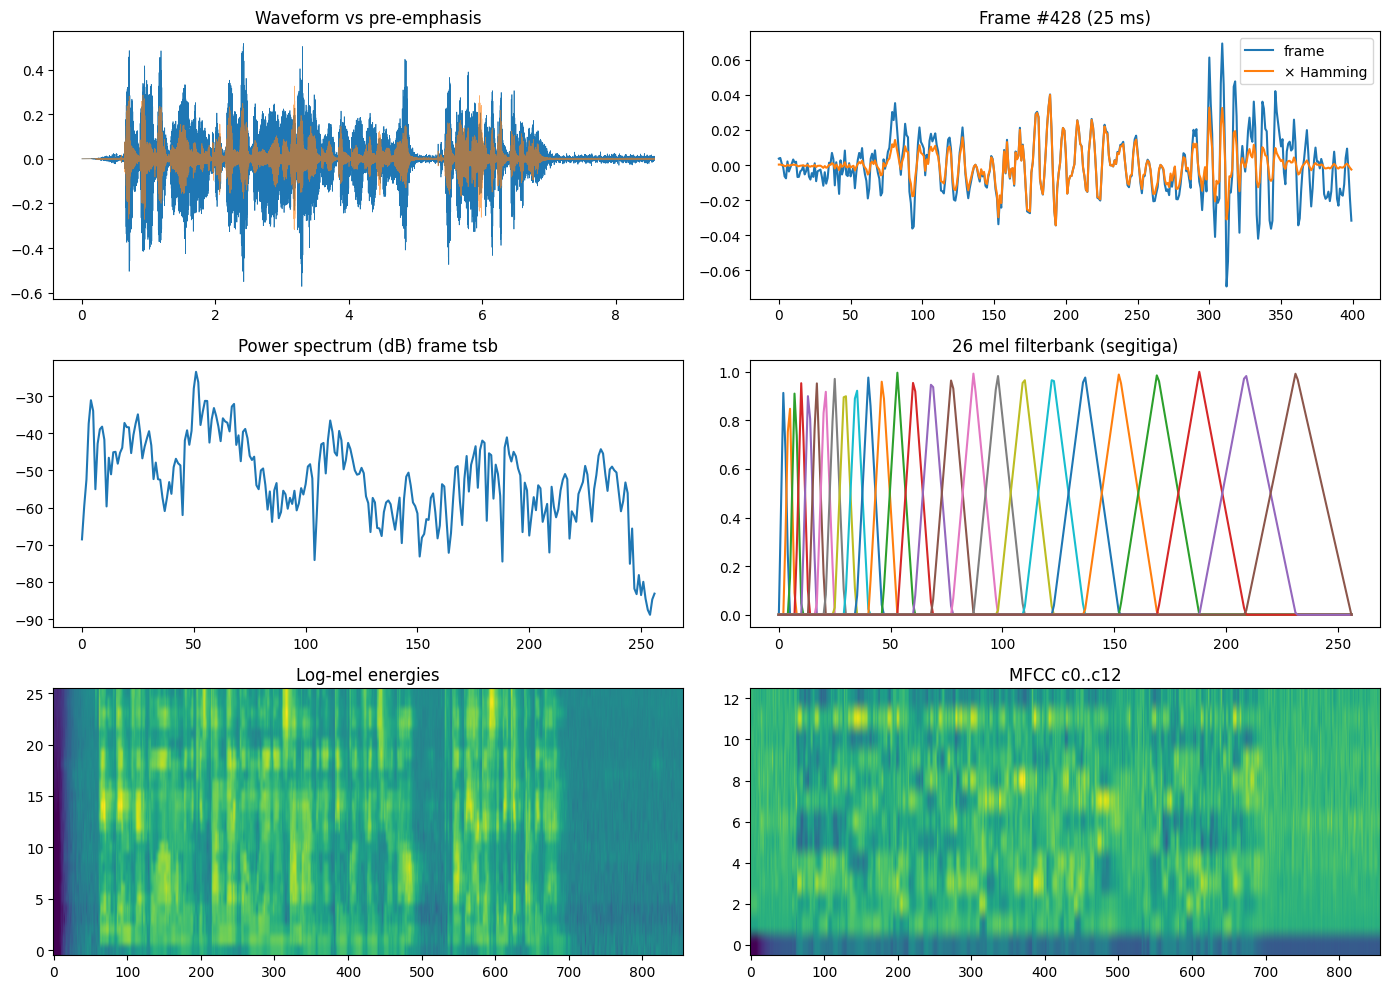

In [8]:
# Visualisasi tiap tahap pada 1 sampel
y = id_test[0]["audio"]["array"]; print("Teks:", id_test[0]["text"])
mf, st = mfcc_manual(y, return_steps=True)
fig, ax = plt.subplots(3, 2, figsize=(14, 10))
t = np.arange(len(y)) / SR
ax[0,0].plot(t, y, lw=.5); ax[0,0].plot(t, st["emph"], lw=.5, alpha=.6); ax[0,0].set_title("Waveform vs pre-emphasis")
k = len(st["frames"]) // 2
ax[0,1].plot(st["frames"][k], label="frame"); ax[0,1].plot(st["win"][k], label="× Hamming"); ax[0,1].legend(); ax[0,1].set_title(f"Frame #{k} (25 ms)")
ax[1,0].plot(10*np.log10(st["power"][k] + 1e-10)); ax[1,0].set_title("Power spectrum (dB) frame tsb")
for f in FB: ax[1,1].plot(f)
ax[1,1].set_title("26 mel filterbank (segitiga)")
ax[2,0].imshow(st["log_mel"].T, aspect="auto", origin="lower"); ax[2,0].set_title("Log-mel energies")
ax[2,1].imshow(mf.T, aspect="auto", origin="lower"); ax[2,1].set_title(f"MFCC c0..c{N_MFCC-1}")
plt.tight_layout(); plt.show()

In [9]:
# Validasi vs librosa (librosa HANYA dipakai untuk mengecek, bukan untuk ekstraksi).
# Setting disamakan: tanpa pre-emphasis & lifter, HTK mel, 26 filter tanpa normalisasi.
fb_lib = librosa.filters.mel(sr=SR, n_fft=512, n_mels=26, htk=True, norm=None)
print("Filterbank manual == librosa:", np.allclose(FB, fb_lib, atol=1e-6))
# librosa menaruh window 400 di tengah frame 512 -> geser 56 sampel; librosa pakai 10·log10 (skala beda, bentuk sama)
m_ours = mfcc_manual(y[56:], pre=0, lifter=0)
S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=512, hop_length=160, win_length=400, window="hamming",
                                   n_mels=26, center=False, htk=True, power=2.0, norm=None)
m_lib = librosa.feature.mfcc(S=librosa.power_to_db(S, top_db=None), n_mfcc=13).T
n = min(len(m_ours), len(m_lib))
corr = [np.corrcoef(m_ours[:n, i], m_lib[:n, i])[0, 1] for i in range(13)]
print("Korelasi per koefisien (manual vs librosa):", np.round(corr, 4))   # harus ≈ 1.0

Filterbank manual == librosa: True
Korelasi per koefisien (manual vs librosa): [1.     0.9998 0.9998 0.9999 1.     0.9999 0.9998 0.9996 0.9998 0.9998
 0.9998 0.9998 0.9997]


## 4. Justifikasi 13 vs 12 Koefisien

| | **13 koefisien (c0–c12)** | **12 koefisien (c1–c12)** |
|---|---|---|
| c0 | ikut | dibuang |
| Arti c0 | rata-rata log energi seluruh filter = **energi/loudness frame** | — |
| Cocok untuk | sistem yang **peduli siapa yang bicara** & kapan bicara (speaker change, VAD) | ASR murni yang **tidak peduli siapa** yang bicara (isi kata saja), karena loudness tidak mengubah kata dan sensitif ke jarak mic |

**Pilihan kita: 13.** Alasannya terikat ke masalah user:
1. **Notulen butuh "siapa bilang apa"** → kita perlu deteksi pergantian speaker. Di meeting UKM, tiap orang duduk di posisi tetap dengan jarak berbeda ke mic laptop dan punya volume bicara khas → c0 membawa informasi speaker yang hilang kalau dibuang.
2. **c0 dipakai sebagai VAD** (energi) untuk memotong stream jadi segmen ucapan → menentukan kapan partial transcript di-*finalize*.
3. Isi kata tetap ditangani Whisper (log-mel internal), jadi c0 tidak merusak akurasi transkripsi.

Klaim ini **diuji** di bawah: speaker identification (GMM per speaker — sesuai materi HMM-GMM) pakai 12 vs 13 koefisien. Pakai rekaman anggota tim sendiri di ruangan meeting (`SPEAKER_DIR`) supaya kondisinya realistis; fallback ke LibriSpeech test-clean. **Laporkan hasil apa adanya** — kalau 13 tidak lebih baik di data kalian, itu temuan yang perlu dibahas di Discussion.

In [10]:
def load_speaker_data(max_spk=10, per_spk=8):
    data = {}
    if os.path.isdir(SPEAKER_DIR):
        for spk in sorted(os.listdir(SPEAKER_DIR))[:max_spk]:
            files = sorted(f for f in os.listdir(os.path.join(SPEAKER_DIR, spk)) if f.lower().endswith((".wav", ".mp3", ".m4a", ".flac")))
            data[spk] = [librosa.load(os.path.join(SPEAKER_DIR, spk, f), sr=SR)[0] for f in files[:per_spk]]
        print("Pakai rekaman sendiri:", {k: len(v) for k, v in data.items()})
    else:
        ls = load_dataset("openslr/librispeech_asr", "clean", split="test", streaming=True)
        for ex in ls:
            s = ex["speaker_id"]
            if s not in data and len(data) >= max_spk: continue
            data.setdefault(s, [])
            if len(data[s]) < per_spk:
                a = ex["audio"]; data[s].append(librosa.resample(a["array"], orig_sr=a["sampling_rate"], target_sr=SR) if a["sampling_rate"] != SR else a["array"])
            if len(data) >= max_spk and all(len(v) >= per_spk for v in data.values()): break
        print("Pakai LibriSpeech test-clean:", {k: len(v) for k, v in data.items()})
    return {k: v for k, v in data.items() if len(v) >= 4}

spk_data = load_speaker_data()

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Pakai LibriSpeech test-clean: {6930: 8, 1320: 8, 5639: 8, 260: 8, 7729: 8, 2094: 8, 3575: 8, 7127: 8, 2961: 8, 8463: 8}


12 (c1-c12)  speaker-ID accuracy = 1.000  (n_test=30)
13 (c0-c12)  speaker-ID accuracy = 1.000  (n_test=30)


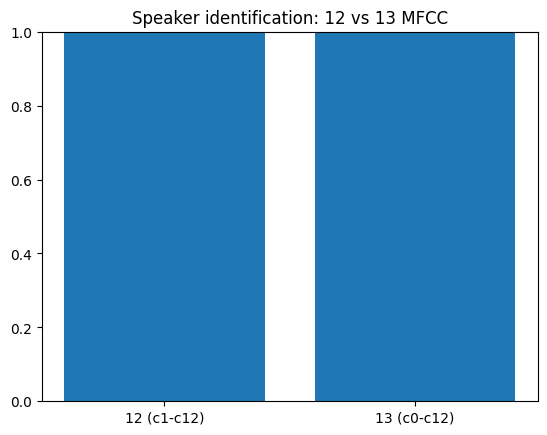

In [11]:
from sklearn.mixture import GaussianMixture

def speaker_id_accuracy(spk_data, coef_slice, n_train=5, n_comp=8):
    # GMM-UBM-style sederhana: 1 GMM diagonal per speaker, klasifikasi = log-likelihood rata-rata tertinggi
    feats = {s: [mfcc_manual(u)[:, coef_slice] for u in utts] for s, utts in spk_data.items()}
    models, tests = {}, []
    for s, F in feats.items():
        ntr = min(n_train, len(F) - 1)
        models[s] = GaussianMixture(n_comp, covariance_type="diag", random_state=SEED, reg_covar=1e-3).fit(np.vstack(F[:ntr]))
        tests += [(s, f) for f in F[ntr:]]
    correct = sum(max(models, key=lambda m: models[m].score(f)) == s for s, f in tests)
    return correct / len(tests), len(tests)

res = {}
for name, sl in {"12 (c1-c12)": slice(1, 13), "13 (c0-c12)": slice(0, 13)}.items():
    acc, n = speaker_id_accuracy(spk_data, sl); res[name] = acc
    print(f"{name:12s} speaker-ID accuracy = {acc:.3f}  (n_test={n})")
plt.bar(res.keys(), res.values()); plt.ylim(0, 1); plt.title("Speaker identification: 12 vs 13 MFCC"); plt.show()

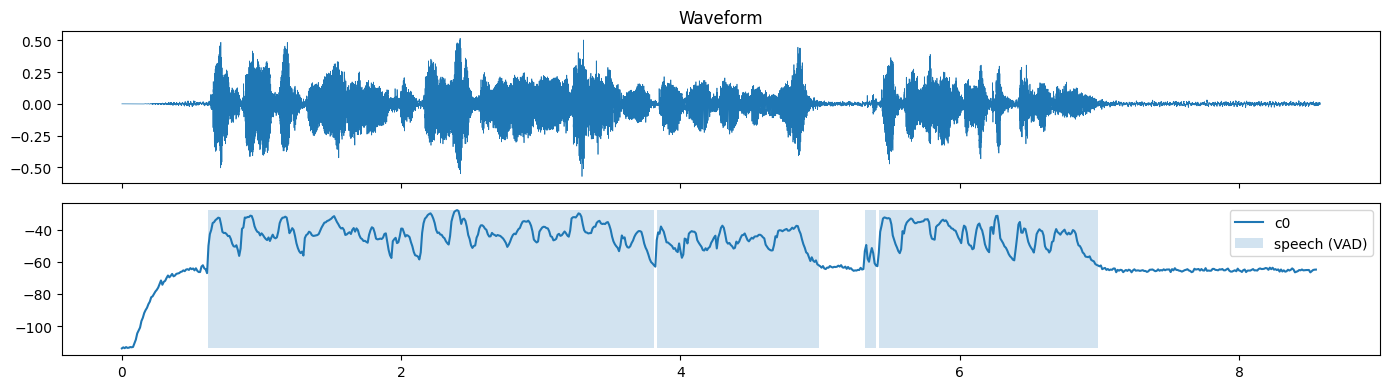

In [12]:
# c0 sebagai VAD: c0 ≈ energi frame -> threshold adaptif dari noise floor
def vad_from_c0(c0, margin=3.0, min_frames=5):
    floor = np.percentile(c0, 10)                 # perkiraan level hening
    speech = c0 > floor + margin
    # smoothing sederhana: buang potongan speech yang terlalu pendek
    out = speech.copy(); i = 0
    while i < len(out):
        if out[i]:
            j = i
            while j < len(out) and out[j]: j += 1
            if j - i < min_frames: out[i:j] = False
            i = j
        else: i += 1
    return out

c0 = mfcc_manual(y)[:, 0]; v = vad_from_c0(c0)
fig, ax = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
ax[0].plot(np.arange(len(y)) / SR, y, lw=.5); ax[0].set_title("Waveform")
tt = np.arange(len(c0)) * 0.01
ax[1].plot(tt, c0, label="c0"); ax[1].fill_between(tt, c0.min(), c0.max(), where=v, alpha=.2, label="speech (VAD)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Baseline: Whisper Pretrained (tanpa fine-tune)

Metrik: **WER** (utama), **CER**, dan **RTF** (real-time factor = waktu proses / durasi audio; < 1 berarti lebih cepat dari real-time).
Kita juga bandingkan *language auto-detect* vs *dipaksa Indonesia* — relevan untuk code-switching.

In [13]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from transformers.models.whisper.english_normalizer import BasicTextNormalizer
normalizer = BasicTextNormalizer()
def norm(t): return " ".join(normalizer(t).split())

def load_whisper(name):
    proc = WhisperProcessor.from_pretrained(name)
    mdl = WhisperForConditionalGeneration.from_pretrained(name).to(DEVICE).eval()
    if DEVICE == "cuda": mdl = mdl.half()
    return proc, mdl

@torch.no_grad()
def transcribe(proc, mdl, audios, language=LANGUAGE, bs=16):
    out = []
    for i in range(0, len(audios), bs):
        feats = proc.feature_extractor(audios[i:i+bs], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE, mdl.dtype)
        kw = dict(task="transcribe", max_new_tokens=220)
        if language: kw["language"] = language
        ids = mdl.generate(feats, **kw)
        out += proc.batch_decode(ids, skip_special_tokens=True)
    return [o.strip() for o in out]

def evaluate(proc, mdl, ds, language=LANGUAGE, noise_snr=None):
    audios = [np.asarray(x["array"], dtype=np.float32) for x in ds["audio"]]
    if noise_snr is not None: audios = [add_babble(a, noise_snr) for a in audios]
    refs = [norm(t) for t in ds["text"]]
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time(); hyps = transcribe(proc, mdl, audios, language)
    if DEVICE == "cuda": torch.cuda.synchronize()
    dur = sum(len(a) for a in audios) / SR
    hyps_n = [norm(h) for h in hyps]
    keep = [i for i, r in enumerate(refs) if r]
    R, H = [refs[i] for i in keep], [hyps_n[i] for i in keep]
    return dict(wer=jiwer.wer(R, H), cer=jiwer.cer(R, H), rtf=(time.time() - t0) / dur), (R, H)

# Babble noise = suara orang lain ngobrol (realistis untuk meeting rame), diambil dari data yang tidak dipakai test
NOISE_BANK = [np.asarray(x["array"], dtype=np.float32) for x in id_train.select(range(len(id_train) - 60, len(id_train)))["audio"]]
def add_babble(a, snr_db, n_talkers=3, rng=np.random):
    noise = np.zeros_like(a)
    for _ in range(n_talkers):
        nb = NOISE_BANK[rng.randint(len(NOISE_BANK))]
        nb = np.tile(nb, int(np.ceil(len(a) / len(nb))))[:len(a)]
        noise += nb
    ps, pn = np.mean(a ** 2) + 1e-10, np.mean(noise ** 2) + 1e-10
    return (a + noise * np.sqrt(ps / (pn * 10 ** (snr_db / 10)))).astype(np.float32)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [14]:
results = {}
for model_name in [BASE_MODEL, COMPARE_MODEL]:
    proc, mdl = load_whisper(model_name)
    for lang in [LANGUAGE, None]:
        for tname, tds in TEST_SETS.items():
            r, _ = evaluate(proc, mdl, tds, language=lang)
            key = f"{model_name.split('/')[-1]} | lang={lang or 'auto'} | {tname}"
            results[key] = r; print(f"{key:55s} WER={r['wer']:.3f} CER={r['cer']:.3f} RTF={r['rtf']:.3f}")
    del mdl; torch.cuda.empty_cache()

preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

whisper-small | lang=indonesian | fleurs_id             WER=0.180 CER=0.054 RTF=0.011
whisper-small | lang=indonesian | synthetic_cs          WER=0.611 CER=0.504 RTF=0.008
whisper-small | lang=auto | fleurs_id                   WER=0.180 CER=0.054 RTF=0.015
whisper-small | lang=auto | synthetic_cs                WER=0.583 CER=0.483 RTF=0.008


## 6. Fine-tune Whisper-base untuk Code-Switching

- Prefix token dipaksa `<|id|><|transcribe|>` → bahasa "matrix" Indonesia; model belajar **membiarkan kata Inggris tetap Inggris** (tidak diterjemahkan).
- Fitur log-mel dihitung **on-the-fly** di collator (hemat disk/RAM).
- Augmentasi: 30% sampel diberi babble noise SNR 5–20 dB (meeting UKM jarang hening).

In [15]:
from dataclasses import dataclass
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

processor = WhisperProcessor.from_pretrained(BASE_MODEL, language=LANGUAGE, task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(BASE_MODEL)
model.generation_config.language = LANGUAGE
model.generation_config.task = "transcribe"
model.generation_config.forced_decoder_ids = None
model.config.forced_decoder_ids = None

@dataclass
class Collator:
    processor: WhisperProcessor
    decoder_start_token_id: int
    augment: bool = False
    def __call__(self, batch):
        audios = [np.asarray(b["audio"]["array"], dtype=np.float32) for b in batch]
        if self.augment:
            audios = [add_babble(a, np.random.uniform(5, 20)) if np.random.rand() < 0.3 else a for a in audios]
        feats = self.processor.feature_extractor(audios, sampling_rate=SR, return_tensors="pt").input_features
        lab = self.processor.tokenizer([b["text"] for b in batch], padding=True, return_tensors="pt")
        labels = lab.input_ids.masked_fill(lab.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all():
            labels = labels[:, 1:]   # model akan menambahkan start token sendiri
        return {"input_features": feats, "labels": labels}

def compute_metrics(pred):
    ids = pred.label_ids.copy(); ids[ids == -100] = processor.tokenizer.pad_token_id
    P = [norm(t) for t in processor.batch_decode(pred.predictions, skip_special_tokens=True)]
    L = [norm(t) for t in processor.batch_decode(ids, skip_special_tokens=True)]
    keep = [i for i, l in enumerate(L) if l]
    return {"wer": jiwer.wer([L[i] for i in keep], [P[i] for i in keep])}

args = Seq2SeqTrainingArguments(
    output_dir=FT_DIR, per_device_train_batch_size=16, per_device_eval_batch_size=16,
    learning_rate=1e-5, warmup_steps=100, max_steps=MAX_STEPS, fp16=(DEVICE == "cuda"),
    eval_strategy="steps", eval_steps=500, save_steps=500, save_total_limit=2, logging_steps=25,
    predict_with_generate=True, generation_max_length=225,
    load_best_model_at_end=True, metric_for_best_model="wer", greater_is_better=False,
    remove_unused_columns=False, dataloader_num_workers=2, report_to="none", seed=SEED)

trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                         data_collator=Collator(processor, model.config.decoder_start_token_id, augment=True),
                         compute_metrics=compute_metrics)
trainer.train()
trainer.save_model(FT_DIR); processor.save_pretrained(FT_DIR)
# Backup ke Drive supaya model tidak hilang kalau Colab disconnect
if os.path.isdir("/content/drive/MyDrive"):
    shutil.copytree(FT_DIR, "/content/drive/MyDrive/ukm_asr/whisper-base-ukm-cs", dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("checkpoint-*"))
    print("Backup model -> Drive: /content/drive/MyDrive/ukm_asr/whisper-base-ukm-cs")

max_steps is given, it will override any value given in num_train_epochs


Step,Training Loss,Validation Loss,Wer
500,0.377900,1.071135,0.692583
1000,0.200200,1.022065,0.465217
1500,0.184500,1.070816,0.500000


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

Backup model -> Drive: /content/drive/MyDrive/ukm_asr/whisper-base-ukm-cs


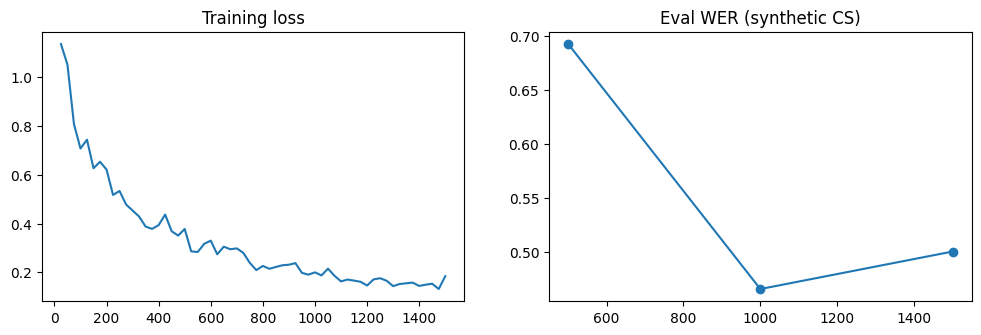

In [16]:
# Kurva training untuk laporan
h = trainer.state.log_history
tr = [(x["step"], x["loss"]) for x in h if "loss" in x]; ev = [(x["step"], x["eval_wer"]) for x in h if "eval_wer" in x]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(*zip(*tr)); ax[0].set_title("Training loss")
if ev: ax[1].plot(*zip(*ev), marker="o"); ax[1].set_title("Eval WER (synthetic CS)")
plt.show()

## 7. Evaluasi: Baseline vs Fine-tuned + Kondisi Noise

- **Baseline condition**: audio bersih.
- **Experimental condition**: babble noise (orang lain ngobrol) SNR 20 / 10 / 5 dB — paling relevan dengan meeting UKM.

In [17]:
proc_ft, mdl_ft = load_whisper(FT_DIR)
proc_b,  mdl_b  = load_whisper(BASE_MODEL)
rows = []
for tname, tds in TEST_SETS.items():
    for snr in [None, 20, 10, 5]:
        for label, (p, m) in {"pretrained": (proc_b, mdl_b), "fine-tuned": (proc_ft, mdl_ft)}.items():
            np.random.seed(SEED)   # noise yang sama untuk kedua model
            r, _ = evaluate(p, m, tds, noise_snr=snr)
            rows.append(dict(test=tname, snr="clean" if snr is None else f"{snr} dB", model=label, **{k: round(v, 3) for k, v in r.items()}))
df = pd.DataFrame(rows); display(df.pivot_table(index=["test", "snr"], columns="model", values=["wer", "rtf"]))
df.to_csv("/content/eval_results.csv", index=False)

rtf                   wer           
model              fine-tuned pretrained fine-tuned pretrained
test         snr                                              
fleurs_id    10 dB      0.007      0.008      0.379      0.549
             20 dB      0.007      0.007      0.255      0.382
             5 dB       0.008      0.011      0.556      1.051
             clean      0.007      0.008      0.232      0.387
synthetic_cs 10 dB      0.008      0.007      1.190      0.892
             20 dB      0.008      0.006      0.887      0.780
             5 dB       0.008      0.008      1.265      1.041
             clean      0.005      0.006      0.237      0.806

## 8. Simulasi Streaming Real-Time (algoritma yang sama dengan web app)

```
mic stream ─► chunk 0.5 s ─► MFCC manual ─► VAD (c0) ─┬─► tiap 1 s: Whisper(segmen berjalan) ─► PARTIAL transcript
                                                       └─► hening ≥ 0.6 s / segmen ≥ 15 s ─► FINAL transcript
                                                                                     └─► embedding MFCC 13-d ─► label "Speaker N"
```
Yang diukur: **update latency** (waktu inference tiap partial), **finalization latency** (dari orang berhenti bicara sampai teks final muncul), dan RTF.

In [18]:
class SpeakerTracker:
    # Online clustering embedding MFCC (mean+std 13-d, dinormalisasi statistik global berjalan)
    def __init__(self, threshold=0.6): self.th, self.cents, self.counts, self.all = threshold, [], [], []
    def assign(self, mf):
        self.all.append(mf); A = np.vstack(self.all); mu, sd = A.mean(0), A.std(0) + 1e-6
        e = np.concatenate([((mf - mu) / sd).mean(0), ((mf - mu) / sd).std(0)])
        if self.cents:
            sims = [np.dot(e, c) / (np.linalg.norm(e) * np.linalg.norm(c) + 1e-9) for c in self.cents]
            k = int(np.argmax(sims))
            if sims[k] >= self.th:
                self.counts[k] += 1; self.cents[k] += (e - self.cents[k]) / self.counts[k]; return k
        self.cents.append(e); self.counts.append(1); return len(self.cents) - 1

def simulate_stream(audio, proc, mdl, chunk_s=0.5, update_s=1.0, silence_s=0.6, max_seg_s=15.0, verbose=True):
    chunk, seg, log, finals = int(chunk_s * SR), [], [], []
    floor, sil, since_update, t_audio = None, 0.0, 0.0, 0.0
    tracker = SpeakerTracker()
    def run(buf):
        t0 = time.time(); txt = transcribe(proc, mdl, [np.concatenate(buf)])[0]; return txt, time.time() - t0
    for i in range(0, len(audio), chunk):
        ch = audio[i:i + chunk]; t_audio += len(ch) / SR
        c0 = mfcc_manual(ch)[:, 0]
        p10 = np.percentile(c0, 10)   # noise floor: turun cepat, naik pelan
        floor = p10 if floor is None else (0.7 * floor + 0.3 * p10 if p10 < floor else floor + 0.02 * (p10 - floor))
        is_speech = (c0 > floor + 3.0).mean() > 0.3
        if is_speech or seg: seg.append(ch)
        sil = 0.0 if is_speech else sil + chunk_s
        since_update += chunk_s
        seg_len = sum(len(s) for s in seg) / SR
        if seg and (sil >= silence_s or seg_len >= max_seg_s):          # FINAL
            txt, dt = run(seg); spk = tracker.assign(mfcc_manual(np.concatenate(seg)))
            finals.append((spk, txt)); log.append(dict(t=t_audio, type="final", latency=dt, text=txt, speaker=spk))
            if verbose: print(f"[{t_audio:6.1f}s] FINAL  Speaker {spk+1}: {txt}   (latency {dt*1000:.0f} ms)")
            seg, since_update = [], 0.0
        elif seg and since_update >= update_s:                           # PARTIAL
            txt, dt = run(seg); log.append(dict(t=t_audio, type="partial", latency=dt, text=txt))
            if verbose: print(f"[{t_audio:6.1f}s] partial: {txt}   ({dt*1000:.0f} ms)")
            since_update = 0.0
    if seg:
        txt, dt = run(seg); spk = tracker.assign(mfcc_manual(np.concatenate(seg))); finals.append((spk, txt))
        log.append(dict(t=t_audio, type="final", latency=dt, text=txt, speaker=spk))
    return finals, pd.DataFrame(log)

# "Meeting" simulasi: beberapa utterance + jeda (pakai rekaman UKM kalau ada)
src = TEST_SETS.get("ukm_real", TEST_SETS["synthetic_cs"])
pieces = [np.zeros(int(0.5 * SR), np.float32)]   # 0.5 s hening untuk kalibrasi VAD
for x in src.select(range(min(5, len(src))))["audio"]:
    pieces += [np.asarray(x["array"], dtype=np.float32), np.zeros(int(0.9 * SR), np.float32)]
meeting = np.concatenate(pieces)
finals, slog = simulate_stream(meeting, proc_ft, mdl_ft)
print("\n=== NOTULEN ==="); [print(f"Speaker {s+1}: {t}") for s, t in finals]
print("\nLatency partial  (ms): mean %.0f | p95 %.0f" % tuple(np.array([slog[slog.type=='partial'].latency.mean(), slog[slog.type=='partial'].latency.quantile(.95)]) * 1000))
print("Latency final    (ms): mean %.0f" % (slog[slog.type=='final'].latency.mean() * 1000))

[   1.0s] partial: The original version was based on the original version of the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the original version. It was based on the origina

> Latency di sini diukur di GPU Colab. Di laporan, ukur juga latency **di browser** (laptop anggota tim/target user) dari web app — itu angka yang dirasakan user. Threshold speaker (`threshold=0.6`) perlu di-tune dengan rekaman meeting kalian.

## 9. Error Analysis (untuk tabel Reference / System Output / Error Type)

In [19]:
def error_table(R, H, max_rows=25):
    rows = []
    for ref, hyp in zip(R, H):
        out = jiwer.process_words(ref, hyp)
        rw, hw = ref.split(), hyp.split()
        for ch in out.alignments[0]:
            if ch.type == "equal": continue
            r = " ".join(rw[ch.ref_start_idx:ch.ref_end_idx]); h = " ".join(hw[ch.hyp_start_idx:ch.hyp_end_idx])
            rows.append(dict(reference=r or "—", output=h or "—", error={"substitute": "Substitution", "delete": "Deletion", "insert": "Insertion"}[ch.type]))
    df = pd.DataFrame(rows)
    print(df.error.value_counts().to_string()); print("\nKata yang paling sering salah:"); print(df[df.error != "Insertion"].reference.value_counts().head(15).to_string())
    return df.head(max_rows)

tname = "ukm_real" if "ukm_real" in TEST_SETS else "synthetic_cs"
_, (R, H) = evaluate(proc_ft, mdl_ft, TEST_SETS[tname])
display(error_table(R, H))

error
Substitution    675
Insertion       190
Deletion         82

Kata yang paling sering salah:
reference
a                     6
and                   6
debu                  5
is                    5
s                     5
the                   5
neglect               4
to                    4
in                    4
lomba perseorangan    3
well                  3
yang                  3
fenomena              3
carpanedo             3
as                    3


,reference,output,error
0,mencorat,mencora,Substitution
1,fission,fusion,Substitution
2,—,it,Insertion
3,ottawa,otawa,Substitution
4,museum,musium,Substitution
5,—,which can cause shrinkage or in extreme cases ...,Insertion
6,tertinggal,tertingkalkan,Substitution
7,pendakian,pendajan,Substitution
8,it,are,Substitution
9,is,—,Deletion


## 10. Export ke ONNX → Hugging Face Hub → dipakai di web app (Vercel)

Web app memanggil model dengan Transformers.js (WebGPU, fallback WASM) **di browser user**. Bobot model hanya di-*download* sekali dari Hub lalu di-cache; inference terjadi lokal di device → tidak ada external ASR API.

In [20]:
# Cell ini bisa dijalankan ulang SENDIRI (mis. setelah restart runtime) selama model fine-tuned masih ada
# di FT_DIR atau di backup Drive -> tidak perlu training ulang.
import os, sys, shutil, functools, importlib, torch
from transformers import WhisperProcessor, WhisperForConditionalGeneration

FT_DIR = globals().get("FT_DIR", "/content/whisper-base-ukm-cs")
if not os.path.exists(os.path.join(FT_DIR, "config.json")):
    FT_DIR = "/content/drive/MyDrive/ukm_asr/whisper-base-ukm-cs"   # pakai backup Drive
assert os.path.exists(os.path.join(FT_DIR, "config.json")), f"Model fine-tuned tidak ditemukan di {FT_DIR}"

# Fix 1: diffusers bawaan Colab bentrok dengan versi pin -> pastikan optimum tidak menyentuhnya.
import optimum.utils.import_utils as _oiu
_oiu._diffusers_available = False
for mod in [m for m in list(sys.modules) if m == "diffusers" or m.startswith("diffusers.") or m.startswith("optimum.exporters")]:
    del sys.modules[mod]          # buang sisa import yang gagal dari percobaan sebelumnya

# Fix 2: torch versi baru default ke exporter dynamo; optimum 1.23 butuh exporter lama.
_orig_export = getattr(torch.onnx.export, "__wrapped__", torch.onnx.export)
@functools.wraps(_orig_export)
def _export_legacy(*a, **k):
    k.setdefault("dynamo", False); return _orig_export(*a, **k)
torch.onnx.export = _export_legacy

from optimum.exporters.onnx import main_export

EAGER_DIR, EXPORT_DIR, HUB_DIR = "/content/ft_eager", "/content/onnx_export", "/content/hub_upload"
shutil.rmtree(EXPORT_DIR, ignore_errors=True)
m = WhisperForConditionalGeneration.from_pretrained(FT_DIR, attn_implementation="eager")
m.save_pretrained(EAGER_DIR); WhisperProcessor.from_pretrained(FT_DIR).save_pretrained(EAGER_DIR)
main_export(EAGER_DIR, output=EXPORT_DIR, task="automatic-speech-recognition-with-past")
WhisperProcessor.from_pretrained(FT_DIR).save_pretrained(EXPORT_DIR)
print(sorted(os.listdir(EXPORT_DIR)))

/usr/local/lib/python3.13/dist-packages/optimum/exporters/onnx/base.py:215: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in staticmethod() if you want to preserve the old behavior
  self._normalized_config = self.NORMALIZED_CONFIG_CLASS(self._config)
/tmp/ipykernel_705/1389543732.py:21: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  k.setdefault("dynamo", False); return _orig_export(*a, **k)
/usr/local/lib/python3.13/dist-packages/transformers/models/whisper/modeling_whisper.py:1017: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow o

['added_tokens.json', 'config.json', 'decoder_model.onnx', 'decoder_model_merged.onnx', 'decoder_with_past_model.onnx', 'encoder_model.onnx', 'generation_config.json', 'merges.txt', 'normalizer.json', 'preprocessor_config.json', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


In [2]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from transformers.models.whisper.english_normalizer import BasicTextNormalizer
EXPORT_DIR = "/content/onnx_export"

In [5]:
# Verifikasi: ONNX harus menghasilkan WER ~sama dengan PyTorch (juga bisa jalan sendiri setelah restart)
import numpy as np, jiwer
from optimum.onnxruntime import ORTModelForSpeechSeq2Seq
from transformers.models.whisper.english_normalizer import BasicTextNormalizer
_bn = BasicTextNormalizer(); _norm = lambda t: " ".join(_bn(t).split())
LANGUAGE = globals().get("LANGUAGE", "indonesian")

if "TEST_SETS" in globals():
    sub = TEST_SETS["synthetic_cs"].select(range(30))
else:   # setelah restart: ambil 30 sampel FLEURS id test
    from datasets import load_dataset, Audio
    sub = load_dataset("parquet", split="test", data_files={"test":
          "hf://datasets/google/fleurs@refs%2Fconvert%2Fparquet/id_id/test/*.parquet"}).select(range(30))
    sub = sub.cast_column("audio", Audio(sampling_rate=16000)).rename_column("raw_transcription", "text")

auds = [np.asarray(x["array"], dtype=np.float32) for x in sub["audio"]]
proc_x = WhisperProcessor.from_pretrained(EXPORT_DIR)
feats = proc_x.feature_extractor(auds, sampling_rate=16000, return_tensors="pt").input_features
kw = dict(language=LANGUAGE, task="transcribe", max_new_tokens=220)

ort_model = ORTModelForSpeechSeq2Seq.from_pretrained(EXPORT_DIR)
hyp_onnx = proc_x.batch_decode(ort_model.generate(feats, **kw), skip_special_tokens=True)
pt_model = WhisperForConditionalGeneration.from_pretrained(FT_DIR).eval()
with torch.no_grad(): hyp_pt = proc_x.batch_decode(pt_model.generate(feats, **kw), skip_special_tokens=True)

R = [_norm(t) for t in sub["text"]]
print("WER PyTorch:", round(jiwer.wer(R, [_norm(h) for h in hyp_pt]), 3),
      "| WER ONNX:", round(jiwer.wer(R, [_norm(h) for h in hyp_onnx]), 3))

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


WER PyTorch: 0.224 | WER ONNX: 0.224


In [7]:
EAGER_DIR, EXPORT_DIR, HUB_DIR = "/content/ft_eager", "/content/onnx_export", "/content/hub_upload"

In [8]:
# Quantize (q8) + susun struktur folder yang dibaca Transformers.js: root = config/tokenizer, onnx/ = model
from onnxruntime.quantization import quantize_dynamic, QuantType
shutil.rmtree(HUB_DIR, ignore_errors=True); os.makedirs(f"{HUB_DIR}/onnx")
for f in os.listdir(EXPORT_DIR):
    if f.endswith(".json") or f.endswith(".txt"): shutil.copy(f"{EXPORT_DIR}/{f}", HUB_DIR)
for name in ["encoder_model", "decoder_model_merged"]:
    shutil.copy(f"{EXPORT_DIR}/{name}.onnx", f"{HUB_DIR}/onnx/{name}.onnx")
    if os.path.exists(f"{EXPORT_DIR}/{name}.onnx_data"): shutil.copy(f"{EXPORT_DIR}/{name}.onnx_data", f"{HUB_DIR}/onnx/")
    quantize_dynamic(f"{EXPORT_DIR}/{name}.onnx", f"{HUB_DIR}/onnx/{name}_quantized.onnx", weight_type=QuantType.QUInt8)
for root, _, files in os.walk(HUB_DIR):
    for f in files: print(os.path.relpath(os.path.join(root, f), HUB_DIR), f"{os.path.getsize(os.path.join(root, f))/1e6:.1f} MB")

tokenizer_config.json 0.3 MB
normalizer.json 0.1 MB
preprocessor_config.json 0.0 MB
vocab.json 1.0 MB
tokenizer.json 3.9 MB
added_tokens.json 0.0 MB
generation_config.json 0.0 MB
config.json 0.0 MB
merges.txt 0.5 MB
special_tokens_map.json 0.0 MB
onnx/decoder_model_merged.onnx 208.4 MB
onnx/encoder_model.onnx 82.4 MB
onnx/encoder_model_quantized.onnx 23.2 MB
onnx/decoder_model_merged_quantized.onnx 208.6 MB


In [15]:
# ==== Simpan ONNX ke Drive + upload ke Hugging Face (satu cell) ====
import os, shutil
from huggingface_hub import login, HfApi

EXPORT_DIR = "/content/onnx_export"
HUB_DIR    = "/content/hub_upload"
DRIVE_DIR  = "/content/drive/MyDrive/ukm_asr/onnx_hub_upload"   # <- lokasi di Drive

# 1) Pastikan Drive ter-mount
if not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")

# 2) Kalau folder hub_upload belum ada / kosong, susun ulang dari hasil export (+ quantize q8)
if not os.path.exists(f"{HUB_DIR}/onnx/encoder_model.onnx"):
    from onnxruntime.quantization import quantize_dynamic, QuantType
    assert os.path.exists(f"{EXPORT_DIR}/encoder_model.onnx"), "Hasil export tidak ada -> jalankan cell export ONNX dulu"
    shutil.rmtree(HUB_DIR, ignore_errors=True); os.makedirs(f"{HUB_DIR}/onnx")
    for f in os.listdir(EXPORT_DIR):
        if f.endswith((".json", ".txt")): shutil.copy(f"{EXPORT_DIR}/{f}", HUB_DIR)
    for name in ["encoder_model", "decoder_model_merged"]:
        shutil.copy(f"{EXPORT_DIR}/{name}.onnx", f"{HUB_DIR}/onnx/")
        if os.path.exists(f"{EXPORT_DIR}/{name}.onnx_data"): shutil.copy(f"{EXPORT_DIR}/{name}.onnx_data", f"{HUB_DIR}/onnx/")
        quantize_dynamic(f"{EXPORT_DIR}/{name}.onnx", f"{HUB_DIR}/onnx/{name}_quantized.onnx", weight_type=QuantType.QUInt8)

# 3) Simpan ke Drive
shutil.copytree(HUB_DIR, DRIVE_DIR, dirs_exist_ok=True)
print("Tersimpan di Drive:", DRIVE_DIR)
for root, _, files in os.walk(DRIVE_DIR):
    for f in sorted(files):
        p = os.path.join(root, f); print("  ", os.path.relpath(p, DRIVE_DIR), f"{os.path.getsize(p)/1e6:.1f} MB")

# 4) Login (paste token BARU tipe Write) + ambil username otomatis
login(new_session=True)
api = HfApi()
username = api.whoami()["name"]
HF_REPO = f"{username}/whisper-base-ukm-codeswitch"
print("Login sebagai:", username, "| repo:", HF_REPO)

# 5) Buat repo public + upload dari folder Drive
api.create_repo(HF_REPO, repo_type="model", private=False, exist_ok=True)
api.upload_folder(folder_path=DRIVE_DIR, repo_id=HF_REPO,
                  commit_message="whisper-base fine-tuned ID-EN code-switching (ONNX)")
print("Selesai:", f"https://huggingface.co/{HF_REPO}")

Tersimpan di Drive: /content/drive/MyDrive/ukm_asr/onnx_hub_upload
   added_tokens.json 0.0 MB
   config.json 0.0 MB
   generation_config.json 0.0 MB
   merges.txt 0.5 MB
   normalizer.json 0.1 MB
   preprocessor_config.json 0.0 MB
   special_tokens_map.json 0.0 MB
   tokenizer.json 3.9 MB
   tokenizer_config.json 0.3 MB
   vocab.json 1.0 MB
   onnx/decoder_model_merged.onnx 208.4 MB
   onnx/decoder_model_merged_quantized.onnx 208.6 MB
   onnx/encoder_model.onnx 82.4 MB
   onnx/encoder_model_quantized.onnx 23.2 MB


Login sebagai: Jennigwen | repo: Jennigwen/whisper-base-ukm-codeswitch


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...decoder_model_merged.onnx:   1%|          | 1.15MB /  208MB            

  ...del_merged_quantized.onnx:   0%|          |  192kB /  209MB            

  ...d/onnx/encoder_model.onnx:   1%|          |  562kB / 82.4MB            

  ...oder_model_quantized.onnx:  16%|#6        | 3.82MB / 23.2MB            

Selesai: https://huggingface.co/Jennigwen/whisper-base-ukm-codeswitch


Di web app (Next.js/Vite di Vercel):
```js
import { pipeline } from "@huggingface/transformers";
const asr = await pipeline("automatic-speech-recognition", "USERNAME/whisper-base-ukm-codeswitch", {
  device: "webgpu",                                   // fallback: "wasm"
  dtype: { encoder_model: "fp32", decoder_model_merged: "q8" },
});
const out = await asr(float32AudioAt16kHz, { language: "indonesian", task: "transcribe" });
```
Loop streaming + MFCC/VAD + speaker label di browser = port langsung dari Bagian 3, 4, dan 8.

## 11. Mode Terjemahan: Full English / Full Indonesia

Desain: **Whisper selalu transcribe** (transkrip asli campur, ini yang dinilai dengan WER) → **lapisan terjemahan terpisah** (Marian / opus-mt, ~75M param, jalan lokal):

| Mode | Model | Di web app (Transformers.js) |
|---|---|---|
| Asli (campur) | — | — |
| Full English | `Helsinki-NLP/opus-mt-id-en` | `Xenova/opus-mt-id-en` |
| Full Indonesia | `Helsinki-NLP/opus-mt-en-id` | `Xenova/opus-mt-en-id` |

Whisper **tidak perlu di-retrain**. Terjemahan hanya untuk segmen **final** (bukan partial) supaya latency live tidak naik.

> opus-mt dilatih dengan kalimat **satu bahasa**, bukan campuran. Bagian ini mengecek seberapa baik hasilnya untuk kalimat campur → masuk Error Analysis / Limitations.

In [12]:
from transformers import MarianMTModel, MarianTokenizer
MT_MODELS = {"en": "Helsinki-NLP/opus-mt-id-en", "id": "Helsinki-NLP/opus-mt-en-id"}
MT = {k: (MarianTokenizer.from_pretrained(v), MarianMTModel.from_pretrained(v).to(DEVICE).eval()) for k, v in MT_MODELS.items()}

@torch.no_grad()
def translate(texts, target):
    # target: "en" = Full English, "id" = Full Indonesia
    tok, m = MT[target]
    batch = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
    out = m.generate(**batch, num_beams=4, max_new_tokens=256)
    return tok.batch_decode(out, skip_special_tokens=True)

# Ganti / tambah dengan kalimat campur dari rekaman meeting UKM kalian
MIXED = [
    "today aku mau discuss tentang budget buat event next month",
    "guys deadline proposal-nya kita push ke Friday ya",
    "jadi basically kita butuh volunteer lima orang untuk registration desk",
    "menurut aku itu kurang efficient, mending kita split jadi dua tim",
    "please semua submit laporan keuangan sebelum meeting minggu depan",
]
rows = []
for target in ["en", "id"]:
    t0 = time.time(); outs = translate(MIXED, target); dt = (time.time() - t0) / len(MIXED)
    for src, out in zip(MIXED, outs): rows.append(dict(mode=f"Full {'English' if target=='en' else 'Indonesia'}", asli=src, terjemahan=out))
    print(f"{target}: rata-rata {dt*1000:.0f} ms / kalimat ({DEVICE})")
pd.set_option("display.max_colwidth", 120); display(pd.DataFrame(rows))

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/796k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/291M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

en: rata-rata 254 ms / kalimat (cuda)
id: rata-rata 53 ms / kalimat (cuda)


,mode,asli,terjemahan
0,Full English,today aku mau discuss tentang budget buat event next month,Today I want to discuss on budget for next month's event.
1,Full English,guys deadline proposal-nya kita push ke Friday ya,"fontcolor="" # FFFF00""guysdeadline proposals fontcolor="" # FFFF00""we pushto Fridayyes"
2,Full English,jadi basically kita butuh volunteer lima orang untuk registration desk,So basically we need a five-man volunteer to registration desk.
3,Full English,"menurut aku itu kurang efficient, mending kita split jadi dua tim","According to me, it's less efficient, so we'd split into two teams."
4,Full English,please semua submit laporan keuangan sebelum meeting minggu depan,Please submit all financial reports before next week's meeting
5,Full Indonesia,today aku mau discuss tentang budget buat event next month,hari ini aku mau mendiskusikan acara anggaran buat bulan depan
6,Full Indonesia,guys deadline proposal-nya kita push ke Friday ya,guys tenggat waktu proposal-nya kita mendorong ke Jumat ya
7,Full Indonesia,jadi basically kita butuh volunteer lima orang untuk registration desk,jadi pada dasarnya kita butuh relawan lima orang untuk pendaftaran meja
8,Full Indonesia,"menurut aku itu kurang efficient, mending kita split jadi dua tim","menurus aku itu kurator efisien, mending kita split jadi dua tim"
9,Full Indonesia,please semua submit laporan keuangan sebelum meeting minggu depan,silahkan semua kirim laporan keuangan pertemuan sebelum minggu depan


In [13]:
# Pipeline lengkap: audio -> Whisper fine-tuned (transkrip campur) -> terjemahan
tname = "ukm_real" if "ukm_real" in TEST_SETS else "synthetic_cs"
sub = TEST_SETS[tname].select(range(min(5, len(TEST_SETS[tname]))))
hyps = transcribe(proc_ft, mdl_ft, [np.asarray(x["array"], dtype=np.float32) for x in sub["audio"]])
display(pd.DataFrame({"referensi": sub["text"], "transkrip (asli)": hyps,
                      "Full English": translate(hyps, "en"), "Full Indonesia": translate(hyps, "id")}))

NameError: name 'TEST_SETS' is not defined

**Evaluasi terjemahan (opsional, untuk laporan).** WER tidak cocok untuk terjemahan. Pakai salah satu:
- **chrF** terhadap terjemahan referensi buatan kalian sendiri: file `mt_refs.csv` (kolom `asli,ref_en,ref_id`), cukup 30–50 kalimat campur.
- **Rating manusia 1–5** saat user testing ("apakah terjemahannya bisa dipahami?").

In [14]:
import sacrebleu, csv
REF_CSV = "/content/drive/MyDrive/ukm_asr/mt_refs.csv"
if os.path.exists(REF_CSV):
    with open(REF_CSV, encoding="utf-8") as f: refs = list(csv.DictReader(f))
    src = [r["asli"] for r in refs]
    for target, col in [("en", "ref_en"), ("id", "ref_id")]:
        hyp = translate(src, target)
        print(f"Full {target.upper()}: chrF = {sacrebleu.corpus_chrf(hyp, [[r[col] for r in refs]]).score:.1f}")
else:
    print("mt_refs.csv belum ada -> skip (pakai rating manusia saat user testing).")

mt_refs.csv belum ada -> skip (pakai rating manusia saat user testing).
